# 19 GHSL Ahmedabad Three-Product Production and Historical Evaluation

This notebook reproduces the validated held-out-city workflow for **Ahmedabad Metropolitan Region**. It first processes all three GHSL products for ten historical epochs, then applies the frozen six-city models without retraining and compares predicted versus actual values for nine five-year transitions.

## Study window

- Seed: 72.5714° E, 23.0225° N
- Projection: ESRI:54009 (World Mollweide)
- Snapped centre: x 6,909,000 m; y 2,817,000 m
- 70 km × 70 km extent: x 6,874,000–6,944,000 m; y 2,782,000–2,852,000 m
- Grid: 70 × 70 = 4,900 one-kilometre cells per epoch
- Actual epochs: 1975–2020 at five-year intervals

## Predictions

The notebook uses the frozen six-city models for built surface, population, and Degree of Urbanisation. Ahmedabad is not added to training or model selection. Each transition uses the actual source epoch, not an earlier predicted epoch. Thus ten observed epochs produce nine prediction comparisons from 1975→1980 through 2015→2020.

## Execution rule

Run cells in order. The production launch is detached. After launching, rerun the monitor until `COMPLETION_RESULT=SUCCESS`; only then continue to the production audit, longitudinal build, and three-product evaluation.


In [1]:
# ============================================================
# CELL 1: BOOTSTRAP
# ============================================================
from google.colab import drive
from pathlib import Path
import base64, csv, hashlib, json, os, shutil, subprocess, textwrap, time

drive.mount('/content/drive',force_remount=False)
D=Path('/content/drive/MyDrive');REMOTE_EXEC=D/'remote_exec.sh';DRIVE_KEY=D/'hadoop-hdfs.pem';LOCAL_KEY=Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT=D/'GHSL_Urban_Growth_Model'/'ahmedabad_unseen_city_evaluation_v1'
TRAINING_MANIFEST=D/'GHSL_Urban_Growth_Model'/'model_training_v1'/'training_manifest.json'
for p in [REMOTE_EXEC,DRIVE_KEY,TRAINING_MANIFEST]:
    if not p.is_file():raise FileNotFoundError(str(p))
REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY,LOCAL_KEY);LOCAL_KEY.chmod(0o600)
ARTIFACT_ROOT.mkdir(parents=True,exist_ok=True)
def run_remote(command,timeout=300,show_output=True,raise_on_error=True):
    r=subprocess.run(['bash',str(REMOTE_EXEC),command],text=True,capture_output=True,timeout=timeout)
    if show_output and r.stdout:print(r.stdout)
    if show_output and r.stderr:print('REMOTE STDERR:');print(r.stderr)
    if raise_on_error and r.returncode:raise RuntimeError('Remote command failed with return code '+str(r.returncode))
    return r
print('CELL 1: SUCCESS')

Mounted at /content/drive
CELL 1: SUCCESS


In [2]:
# ============================================================
# CELL 2: FROZEN AHMEDABAD CONFIGURATION
# ============================================================
ACTIVE_CITY_SLUG='ahmedabad'
ACTIVE_CITY={
 'city_name':'Ahmedabad Metropolitan Region','city_slug':'ahmedabad','seed_lon':72.5714,'seed_lat':23.0225,
 'target_crs':'ESRI:54009','expected_grid_cells':4900,'expected_complete_cells':4900,'expected_partial_cells':0,
 'extent_mollweide':{'min_x':6874000.0,'min_y':2782000.0,'max_x':6944000.0,'max_y':2852000.0},
 'hdfs_output_base':'hdfs://localhost:9000/data/ghsl/curated/cities/city=ahmedabad',
 'remote_work_dir':'/home/ubuntu/ghsl_multicity/ahmedabad'
}
assert ACTIVE_CITY['extent_mollweide']['max_x']-ACTIVE_CITY['extent_mollweide']['min_x']==70000
assert ACTIVE_CITY['extent_mollweide']['max_y']-ACTIVE_CITY['extent_mollweide']['min_y']==70000
EXPECTED_EPOCHS=[1975,1980,1985,1990,1995,2000,2005,2010,2015,2020]
AHMEDABAD_HDFS_ROOT=ACTIVE_CITY['hdfs_output_base']
AHMEDABAD_LONG='/data/ghsl/modeling/ahmedabad_longitudinal_v1'
AHMEDABAD_TRANS='/data/ghsl/modeling/ahmedabad_transitions_v1'
AHMEDABAD_EVAL='/data/ghsl/modeling/evaluation/ahmedabad_unseen_city_v1'
EVAL_MODEL='/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
print(json.dumps(ACTIVE_CITY,indent=2));print('CELL 2: SUCCESS')

{
  "city_name": "Ahmedabad Metropolitan Region",
  "city_slug": "ahmedabad",
  "seed_lon": 72.5714,
  "seed_lat": 23.0225,
  "target_crs": "ESRI:54009",
  "expected_grid_cells": 4900,
  "expected_complete_cells": 4900,
  "expected_partial_cells": 0,
  "extent_mollweide": {
    "min_x": 6874000.0,
    "min_y": 2782000.0,
    "max_x": 6944000.0,
    "max_y": 2852000.0
  },
  "hdfs_output_base": "hdfs://localhost:9000/data/ghsl/curated/cities/city=ahmedabad",
  "remote_work_dir": "/home/ubuntu/ghsl_multicity/ahmedabad"
}
CELL 2: SUCCESS


In [3]:
# ============================================================
# CELL 3: FROZEN BASELINE AND HDFS PREFLIGHT
# ============================================================
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
BASE=/home/ubuntu/ghsl_multicity_baseline
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{print $2}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
for f in baseline_manifest.json SHA256SUMS README.txt source_city_config.json batch/run_city_epochs.py templates/population_epoch_template.py templates/smod_epoch_template.py templates/built_surface_epoch_template.py;do test -f "$BASE/$f";done
cd "$BASE";sha256sum -c SHA256SUMS
if hdfs dfs -test -e /data/ghsl/curated/cities/city=ahmedabad;then echo 'ERROR: Ahmedabad HDFS root already exists. Audit it before rebuilding.';exit 30;fi
echo AHMEDABAD_BASELINE_PREFLIGHT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 3: SUCCESS')

baseline_manifest.json: OK
batch/run_city_epochs.py: OK
source_city_config.json: OK
templates/built_surface_epoch_template.py: OK
templates/population_epoch_template.py: OK
templates/smod_epoch_template.py: OK
AHMEDABAD_BASELINE_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 3: SUCCESS


In [4]:
# ============================================================
# CELL 4: CREATE AHMEDABAD WORKSPACE FROM FROZEN BASELINE
# Refuses an incomplete or existing workspace.
# ============================================================
config_b64=base64.b64encode((json.dumps(ACTIVE_CITY,indent=2,sort_keys=True)+'\n').encode()).decode()
builder=r"""from pathlib import Path
import ast,hashlib,json,py_compile,shutil,sys,time
BASE=Path('/home/ubuntu/ghsl_multicity_baseline');TARGET=Path('/home/ubuntu/ghsl_multicity/ahmedabad');CONFIG=Path(sys.argv[1])
def sha(p):
 h=hashlib.sha256();h.update(p.read_bytes());return h.hexdigest()
cfg=json.loads(CONFIG.read_text());src=json.loads((BASE/'source_city_config.json').read_text())
if cfg['city_slug']!='ahmedabad' or cfg['extent_mollweide']!={'min_x':6874000.0,'min_y':2782000.0,'max_x':6944000.0,'max_y':2852000.0}:raise RuntimeError('Ahmedabad config mismatch')
manifest=TARGET/'ahmedabad_workspace_manifest.json'
if TARGET.exists():
 if manifest.is_file():print('AHMEDABAD_WORKSPACE_ALREADY_EXISTS');print('AHMEDABAD_WORKSPACE_BUILD_SUCCESS');raise SystemExit(0)
 raise RuntimeError('Incomplete Ahmedabad workspace exists: '+str(TARGET))
source_extent=src['extent_mollweide'];target_extent=cfg['extent_mollweide']
repl=[(src['remote_work_dir'],cfg['remote_work_dir']),('city='+src['city_slug'],'city=ahmedabad'),(src['city_slug'],'ahmedabad'),(src['city_name'],cfg['city_name'])]
for k in ['min_x','min_y','max_x','max_y']:
 repl += [(str(float(source_extent[k])),str(float(target_extent[k]))),(str(int(source_extent[k])),str(int(target_extent[k])))]
def param(x):
 for a,b in repl:x=x.replace(a,b)
 return x
try:
 for d in ['templates','programs','batch']:(TARGET/d).mkdir(parents=True,exist_ok=False)
 hashes={}
 for n in ['population_epoch_template.py','smod_epoch_template.py','built_surface_epoch_template.py']:
  dst=TARGET/'templates'/n;txt=param((BASE/'templates'/n).read_text());compile(txt,str(dst),'exec');dst.write_text(txt);py_compile.compile(str(dst),doraise=True);hashes[n]=sha(dst)
 driver=TARGET/'batch'/'run_city_epochs.py';txt=param((BASE/'batch'/'run_city_epochs.py').read_text());tree=ast.parse(txt)
 node=next((n for n in tree.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='EXPECTED_TEMPLATE_SHA256' for t in n.targets)),None)
 if node is None:raise RuntimeError('Checksum dictionary missing')
 dct={'population':hashes['population_epoch_template.py'],'smod':hashes['smod_epoch_template.py'],'built_surface':hashes['built_surface_epoch_template.py']}
 lines=txt.splitlines(keepends=True);lines[node.lineno-1:node.end_lineno]=['EXPECTED_TEMPLATE_SHA256 = '+repr(dct)+'\n'];txt=''.join(lines)
 compile(txt,str(driver),'exec');driver.write_text(txt);py_compile.compile(str(driver),doraise=True)
 (TARGET/'city_config.json').write_text(json.dumps(cfg,indent=2,sort_keys=True)+'\n')
 combined=txt+''.join((TARGET/'templates'/n).read_text() for n in hashes)
 for forbidden in [src['remote_work_dir'],'city='+src['city_slug'],src['city_name']]:
  if forbidden in combined:raise RuntimeError('Source-city leakage: '+forbidden)
 for required in ['/home/ubuntu/ghsl_multicity/ahmedabad','city=ahmedabad','6874000','2782000','6944000','2852000']:
  if required not in combined:raise RuntimeError('Missing Ahmedabad parameter: '+required)
 for p in TARGET.rglob('__pycache__'):shutil.rmtree(p)
 manifest.write_text(json.dumps({'city_slug':'ahmedabad','city_name':cfg['city_name'],'workspace':str(TARGET),'driver_sha256':sha(driver),'template_sha256':dct,'extent_mollweide':target_extent,'expected_grid_cells':4900,'created_at_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())},indent=2,sort_keys=True)+'\n')
except Exception:
 if TARGET.exists():shutil.rmtree(TARGET)
 raise
print('AHMEDABAD_WORKSPACE_BUILD_SUCCESS')
"""
compile(builder,'builder.py','exec');builder_b64=base64.b64encode(builder.encode()).decode()
cmd=f"""set -e
B=/tmp/build_ahmedabad_workspace.py;C=/tmp/ahmedabad_city_config.json
echo '{builder_b64}'|base64 -d > "$B";echo '{config_b64}'|base64 -d > "$C";python3 -m py_compile "$B";python3 "$B" "$C";rm -f "$B" "$C"
"""
r=run_remote(cmd,300)
print('CELL 4: SUCCESS')

AHMEDABAD_WORKSPACE_BUILD_SUCCESS

REMOTE STDERR:

CELL 4: SUCCESS


In [5]:
# ============================================================
# CELL 5: AHMEDABAD SOURCE-TILE EXPECTATION PATCH
# Ahmedabad's 70 km window is expected to intersect 3 x 3 source tiles.
# This modifies only the Ahmedabad workspace, refreshes checksums,
# and runs before production launch. Frozen baseline and HDFS: unchanged.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=r"""set -e
ROOT='__ROOT__';EXPECTED=9
python3 - "$ROOT" "$EXPECTED" <<'PY_REMOTE'
from pathlib import Path
import ast,hashlib,json,py_compile,re,sys
root=Path(sys.argv[1]);expected=int(sys.argv[2]);driver=root/'batch'/'run_city_epochs.py'
templates={'population':root/'templates'/'population_epoch_template.py','smod':root/'templates'/'smod_epoch_template.py','built_surface':root/'templates'/'built_surface_epoch_template.py'}
def sha(p):
 h=hashlib.sha256();h.update(p.read_bytes());return h.hexdigest()
def patch(text):
 text=re.sub(r'Expected\s+16\s+selected\s+tiles',f'Expected {expected} selected tiles',text)
 text=re.sub(r'len\(\s*selected_tiles\s*\)\s*!=\s*16',f'len(selected_tiles) != {expected}',text)
 text=re.sub(r'selected_tile_count\s*!=\s*16',f'selected_tile_count != {expected}',text)
 text=re.sub(r'selected_tiles_count\s*!=\s*16',f'selected_tiles_count != {expected}',text)
 return text
changed=[]
for stage,path in templates.items():
 old=path.read_text();new=patch(old);compile(new,str(path),'exec')
 if new!=old:path.write_text(new);changed.append(stage)
 py_compile.compile(str(path),doraise=True)
hashes={stage:sha(path) for stage,path in templates.items()}
source=driver.read_text();tree=ast.parse(source);node=next((n for n in tree.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='EXPECTED_TEMPLATE_SHA256' for t in n.targets)),None)
if node is None:raise RuntimeError('EXPECTED_TEMPLATE_SHA256 missing')
lines=source.splitlines(keepends=True);lines[node.lineno-1:node.end_lineno]=['EXPECTED_TEMPLATE_SHA256 = '+repr(hashes)+'\n'];source=''.join(lines);compile(source,str(driver),'exec');driver.write_text(source);py_compile.compile(str(driver),doraise=True)
manifest=root/'ahmedabad_workspace_manifest.json'
if manifest.is_file():
 m=json.loads(manifest.read_text());m['selected_source_tile_expectation']=expected;m['driver_sha256']=sha(driver);m['template_sha256']=hashes;manifest.write_text(json.dumps(m,indent=2,sort_keys=True)+'\n')
print(json.dumps({'expected_selected_tiles':expected,'modified_templates':changed,'template_sha256':hashes},indent=2,sort_keys=True))
print('AHMEDABAD_TILE_EXPECTATION_PATCH_SUCCESS')
PY_REMOTE
python3 -m py_compile "$ROOT/batch/run_city_epochs.py" "$ROOT"/templates/*.py
echo AHMEDABAD_TILE_PATCH_REMOTE_SUCCESS
""".replace('__ROOT__',root)
r=run_remote(cmd,600)
if 'AHMEDABAD_TILE_EXPECTATION_PATCH_SUCCESS' not in r.stdout or 'AHMEDABAD_TILE_PATCH_REMOTE_SUCCESS' not in r.stdout:raise RuntimeError('Ahmedabad tile patch failed')
print('Frozen baseline modified: NO');print('HDFS modified: NO');print('CELL 5: SUCCESS')

{
  "expected_selected_tiles": 9,
  "modified_templates": [
    "population"
  ],
  "template_sha256": {
    "built_surface": "fa137236258575f7683bcafa910f8b3828d29a48edc71bcfcc331712ea82681e",
    "population": "27271286982fe3884c0636544f5c949645a101638b2f01e18307ff50c7293fa8",
    "smod": "0d5e62e1239312bda56641d56d67f1c30e27a365206686501e82f7f8f7dbd6e0"
  }
}
AHMEDABAD_TILE_EXPECTATION_PATCH_SUCCESS
AHMEDABAD_TILE_PATCH_REMOTE_SUCCESS

REMOTE STDERR:

Frozen baseline modified: NO
HDFS modified: NO
CELL 5: SUCCESS


In [6]:
# ============================================================
# CELL 5: STATIC AHMEDABAD WORKSPACE AUDIT
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py"
for f in "$DRIVER" "$ROOT/city_config.json" "$ROOT/ahmedabad_workspace_manifest.json" "$ROOT/templates/population_epoch_template.py" "$ROOT/templates/smod_epoch_template.py" "$ROOT/templates/built_surface_epoch_template.py";do test -f "$f";done
PYTHONPYCACHEPREFIX=/tmp/ahmedabad_compile python3 -m py_compile "$DRIVER" "$ROOT"/templates/*.py
python3 - "$ROOT" <<'PY_REMOTE'
from pathlib import Path
import ast,json,sys
r=Path(sys.argv[1]);cfg=json.loads((r/'city_config.json').read_text());src=(r/'batch'/'run_city_epochs.py').read_text()+''.join(p.read_text() for p in (r/'templates').glob('*.py'))
assert cfg['city_slug']=='ahmedabad' and cfg['expected_grid_cells']==4900 and cfg['target_crs']=='ESRI:54009'
assert cfg['extent_mollweide']=={{'min_x':6874000.0,'min_y':2782000.0,'max_x':6944000.0,'max_y':2852000.0}}
for x in ['city=ahmedabad','6874000','2782000','6944000','2852000']:assert x in src,x
for x in ['city=pune_metro','city=hyderabad','Pune Metropolitan Region','Hyderabad Metropolitan Region']:assert x not in src,x
print('AHMEDABAD_STRUCTURAL_AUDIT_SUCCESS')
PY_REMOTE
test ! -e "$ROOT/batch/city.pid";test ! -e "$ROOT/batch/city.log"
rm -rf /tmp/ahmedabad_compile
echo AHMEDABAD_STATIC_AUDIT_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 5: SUCCESS')

AHMEDABAD_STRUCTURAL_AUDIT_SUCCESS
AHMEDABAD_STATIC_AUDIT_SUCCESS

REMOTE STDERR:

CELL 5: SUCCESS


In [7]:
# ============================================================
# CELL 6: ALL-EPOCH GENERATOR SMOKE TEST
# Generates and compiles 30 programs in /tmp only.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
python3 - '{root}' <<'PY_REMOTE'
from pathlib import Path
import ast,py_compile,shutil,sys,tempfile
root=Path(sys.argv[1]);driver=root/'batch'/'run_city_epochs.py';tree=ast.parse(driver.read_text())
allowed=(ast.Import,ast.ImportFrom,ast.Assign,ast.AnnAssign,ast.FunctionDef,ast.AsyncFunctionDef,ast.ClassDef)
module=ast.Module(body=[n for n in tree.body if isinstance(n,allowed)],type_ignores=[]);ast.fix_missing_locations(module)
ns={{'__file__':str(driver),'__name__':'ahmedabad_smoke'}};exec(compile(module,str(driver),'exec'),ns)
factories={{'population':ns['generate_population_program'],'smod':ns['generate_smod_program'],'built_surface':ns['generate_built_program']}}
tmp=Path(tempfile.mkdtemp(prefix='ahmedabad_smoke_'));count=0
try:
 for e in [1975,1980,1985,1990,1995,2000,2005,2010,2015,2020]:
  d=tmp/str(e);d.mkdir()
  for stage,f in factories.items():
   obj=f(e,d);p=obj if isinstance(obj,Path) else Path(obj)
   if not p.is_file():raise RuntimeError('Program missing '+stage+str(e))
   py_compile.compile(str(p),doraise=True);txt=p.read_text()
   assert 'city=ahmedabad' in txt and ('EPOCH='+str(e)) in txt.replace(' ','') and ('epoch='+str(e)+'/') in txt
   assert 'city=pune_metro' not in txt and 'city=hyderabad' not in txt
   count+=1;print('PASS',e,stage,p.name)
 if count!=30:raise RuntimeError('Expected 30 programs')
finally:shutil.rmtree(tmp)
print('ALL_30_AHMEDABAD_PROGRAMS_COMPILE_PASS')
PY_REMOTE
echo CELL_6_REMOTE_SUCCESS
"""
r=run_remote(cmd,300)
print('CELL 6: SUCCESS')

PASS 1975 population population_1975.py
PASS 1975 smod smod_1975.py
PASS 1975 built_surface built_surface_1975.py
PASS 1980 population population_1980.py
PASS 1980 smod smod_1980.py
PASS 1980 built_surface built_surface_1980.py
PASS 1985 population population_1985.py
PASS 1985 smod smod_1985.py
PASS 1985 built_surface built_surface_1985.py
PASS 1990 population population_1990.py
PASS 1990 smod smod_1990.py
PASS 1990 built_surface built_surface_1990.py
PASS 1995 population population_1995.py
PASS 1995 smod smod_1995.py
PASS 1995 built_surface built_surface_1995.py
PASS 2000 population population_2000.py
PASS 2000 smod smod_2000.py
PASS 2000 built_surface built_surface_2000.py
PASS 2005 population population_2005.py
PASS 2005 smod smod_2005.py
PASS 2005 built_surface built_surface_2005.py
PASS 2010 population population_2010.py
PASS 2010 smod smod_2010.py
PASS 2010 built_surface built_surface_2010.py
PASS 2015 population population_2015.py
PASS 2015 smod smod_2015.py
PASS 2015 built_surf

In [8]:
# ============================================================
# CELL 7: DETACHED AHMEDABAD PRODUCTION LAUNCH
# Skip this cell if Ahmedabad production already completed.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
ROOT='{root}';DRIVER="$ROOT/batch/run_city_epochs.py";PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log"
for d in NameNode DataNode SecondaryNameNode;do jps|awk '{{print $2}}'|grep -qx "$d";done
hdfs dfsadmin -safemode get|grep -qi 'Safe mode is OFF'
if [ -f "$PID" ] && kill -0 "$(cat "$PID")" 2>/dev/null;then echo 'ERROR: Ahmedabad job already running';exit 30;fi
rm -f "$PID";test ! -e "$LOG" || mv "$LOG" "$LOG.before_launch.$(date -u +%Y%m%dT%H%M%SZ)"
nohup python3 "$DRIVER" >"$LOG" 2>&1 </dev/null & echo $! > "$PID";sleep 5
kill -0 "$(cat "$PID")";ps -p "$(cat "$PID")" -o pid,etime,%cpu,%mem,cmd
echo AHMEDABAD_DETACHED_LAUNCH_SUCCESS
"""
r=run_remote(cmd,90)
print('Safe to close Colab. Monitor with Cell 8.')
print('CELL 7: SUCCESS')

    PID     ELAPSED %CPU %MEM CMD
  95722       00:05  0.3  0.2 python3 /home/ubuntu/ghsl_multicity/ahmedabad/batch/run_city_epochs.py
AHMEDABAD_DETACHED_LAUNCH_SUCCESS

REMOTE STDERR:

Safe to close Colab. Monitor with Cell 8.
CELL 7: SUCCESS


In [27]:
# ============================================================
# CELL 8: AHMEDABAD PRODUCTION MONITOR
# Rerun this read-only cell until COMPLETION_RESULT=SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir']
cmd=f"""set +e
source /home/ubuntu/ghsl-sedona-env.sh 2>/dev/null
ROOT='{root}';PID="$ROOT/batch/city.pid";LOG="$ROOT/batch/city.log";MAN="$ROOT/batch/batch_manifest.tsv"
P=N/A;STATUS=UNKNOWN;[ -f "$PID" ]&&P=$(cat "$PID")&&{{ kill -0 "$P" 2>/dev/null&&STATUS=RUNNING||STATUS=STOPPED; }}
echo PID=$P;echo STATUS=$STATUS;[ "$STATUS" = RUNNING ]&&ps -p "$P" -o pid,etime,%cpu,%mem,cmd
echo LATEST_LOG;[ -f "$LOG" ]&&tail -150 "$LOG";echo CURRENT_MANIFEST;[ -f "$MAN" ]&&cat "$MAN"
if [ "$STATUS" = RUNNING ];then echo COMPLETION_RESULT=IN_PROGRESS;elif grep -q 'BATCH PIPELINE: SUCCESS' "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=SUCCESS;elif grep -q Traceback "$LOG" 2>/dev/null;then echo COMPLETION_RESULT=FAILED;else echo COMPLETION_RESULT=UNKNOWN;fi
exit 0
"""
run_remote(cmd,180)
print('CELL 8 MONITOR COMPLETE')

PID=95722
STATUS=STOPPED
LATEST_LOG
VALIDATE NEW ENRICHED 2015
Command: spark-submit --master local[1] --driver-memory 1g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=2 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=false --conf spark.driver.maxResultSize=256m /home/ubuntu/ghsl_multicity/ahmedabad/programs/epoch_2015/validate_enriched_2015.py


Return code: 0
Elapsed seconds: 12.63
enriched 2015: BUILT AND VALIDATED

EPOCH 2015: COMPLETE
Epoch elapsed minutes: 9.71

################################################################################
EPOCH 2020 (10/10)
################################################################################

RUN POPULATION 2020
Command: spark-submit --master local[1] --driver-memory 5g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=4 --conf spark.default.parallelism=2 --conf spark.sql.adaptive.enabled=false --conf spark.sql.codegen.wholeStage=fals

In [28]:
# ============================================================
# CELL 9: FINAL 40-PATH AND 49,000-ROW AHMEDABAD AUDIT
# Run only after monitor shows SUCCESS.
# ============================================================
root=ACTIVE_CITY['remote_work_dir'];slug=ACTIVE_CITY_SLUG
cmd=f"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${{HADOOP_HOME}}/bin:${{HADOOP_HOME}}/sbin:${{PATH}}"
grep -q 'BATCH PIPELINE: SUCCESS' '{root}/batch/city.log'
n=0
for e in 1975 1980 1985 1990 1995 2000 2005 2010 2015 2020;do
 for s in population smod built_surface;do hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/product=$s/epoch=$e/grid_1km;n=$((n+1));done
 hdfs dfs -test -e /data/ghsl/curated/cities/city={slug}/enriched_grid_year/epoch=$e;n=$((n+1));echo Epoch $e: 4/4 paths PASS
done
test $n -eq 40;echo ALL_40_AHMEDABAD_PATHS_PASS
"""
r=run_remote(cmd,300)
print('CELL 9: SUCCESS')

Epoch 1975: 4/4 paths PASS
Epoch 1980: 4/4 paths PASS
Epoch 1985: 4/4 paths PASS
Epoch 1990: 4/4 paths PASS
Epoch 1995: 4/4 paths PASS
Epoch 2000: 4/4 paths PASS
Epoch 2005: 4/4 paths PASS
Epoch 2010: 4/4 paths PASS
Epoch 2015: 4/4 paths PASS
Epoch 2020: 4/4 paths PASS
ALL_40_AHMEDABAD_PATHS_PASS

REMOTE STDERR:

CELL 9: SUCCESS


In [29]:
# ============================================================
# CELL 10: BUILD HARMONIZED AHMEDABAD LONGITUDINAL DATASET
# ============================================================
payload=base64.b64encode(json.dumps({'root':AHMEDABAD_HDFS_ROOT+'/enriched_grid_year','out':AHMEDABAD_LONG,'epochs':EXPECTED_EPOCHS}).encode()).decode()
cmd=r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop;export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
P=/tmp/ahmedabad_long.json;S=/tmp/ahmedabad_long.py;echo __P__|base64 -d > "$P"
cat > "$S" <<'PY_REMOTE'
from pyspark.sql import SparkSession,functions as F
from functools import reduce
import json,sys
p=json.load(open(sys.argv[1]));s=SparkSession.builder.appName('Ahmedabad-Longitudinal').getOrCreate();s.sparkContext.setLogLevel('WARN')
try:
 fs=s._jvm.org.apache.hadoop.fs.FileSystem.get(s._jsc.hadoopConfiguration());op=s._jvm.org.apache.hadoop.fs.Path(p['out'])
 if fs.exists(op):raise RuntimeError('Refusing overwrite: '+p['out'])
 frames=[]
 for e in p['epochs']:
  d=s.read.parquet(p['root']+'/epoch='+str(e))
  if d.count()!=4900 or d.select('grid_cell_id').distinct().count()!=4900:raise RuntimeError('Invalid epoch '+str(e))
  for c in ['built_observed_grid_area_m2','built_coverage_fraction']:d=d.withColumn(c,F.col(c).cast('double'))
  for c in ['epoch','city_name','city_slug']:
   if c in d.columns:d=d.drop(c)
  frames.append(d.withColumn('city_name',F.lit('Ahmedabad Metropolitan Region')).withColumn('city_slug',F.lit('ahmedabad')).withColumn('epoch',F.lit(e).cast('int')))
 out=reduce(lambda a,b:a.unionByName(b),frames)
 if out.count()!=49000 or out.select('epoch','grid_cell_id').distinct().count()!=49000:raise RuntimeError('Longitudinal validation failed')
 out.repartition('epoch').write.mode('errorifexists').partitionBy('epoch').parquet(p['out'])
 if s.read.parquet(p['out']).count()!=49000:raise RuntimeError('Reread failed')
 print('AHMEDABAD_LONGITUDINAL_SUCCESS')
finally:s.stop()
PY_REMOTE
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$S" "$P";rm -f "$S" "$P"
""".replace('__P__',payload)
r=run_remote(cmd,7200)
print('CELL 10: SUCCESS')

AHMEDABAD_LONGITUDINAL_SUCCESS

REMOTE STDERR:
26/11/15 13:27:14 INFO SparkContext: Running Spark version 3.5.9
26/11/15 13:27:14 INFO SparkContext: OS info Linux, 7.0.0-1016-aws, amd64
26/11/15 13:27:14 INFO SparkContext: Java version 11.0.32.1
26/11/15 13:27:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 13:27:14 INFO ResourceUtils: ==============================================================
26/11/15 13:27:14 INFO ResourceUtils: No custom resources configured for spark.driver.
26/11/15 13:27:14 INFO ResourceUtils: ==============================================================
26/11/15 13:27:14 INFO SparkContext: Submitted application: Ahmedabad-Longitudinal
26/11/15 13:27:14 INFO ResourceProfile: Default ResourceProfile created, executor resources: Map(cores -> name: cores, amount: 1, script: , vendor: , memory -> name: memory, amount: 1024, script: , vendor: , offHeap -> name: offHeap, amoun

# Part II: Ahmedabad three-product prediction and comparison

Continue only after the production monitor reports success and the 49,000-row longitudinal dataset has been created.

In [30]:
# ============================================================
# CELL 1: BOOTSTRAP, PATHS, AND CONSTANTS
# ============================================================
from google.colab import drive
from pathlib import Path
from IPython.display import display
import base64, csv, json, os, shutil, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = Path('/content/drive/MyDrive')
REMOTE_EXEC = DRIVE_ROOT / 'remote_exec.sh'
DRIVE_KEY = DRIVE_ROOT / 'hadoop-hdfs.pem'
LOCAL_KEY = Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT = DRIVE_ROOT / 'GHSL_Urban_Growth_Model' / 'ahmedabad_three_product_evaluation_v1'
FIGURE_ROOT = ARTIFACT_ROOT / 'figures'
SPATIAL_ROOT = FIGURE_ROOT / 'spatial'

for required_path in [REMOTE_EXEC, DRIVE_KEY]:
    if not required_path.is_file():
        raise FileNotFoundError(str(required_path))

REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():
    LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY, LOCAL_KEY)
LOCAL_KEY.chmod(0o600)

ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
SPATIAL_ROOT.mkdir(parents=True, exist_ok=True)


def run_remote(command, timeout=300, show_output=True, raise_on_error=True):
    result = subprocess.run(
        ['bash', str(REMOTE_EXEC), command],
        text=True,
        capture_output=True,
        timeout=timeout,
    )
    if show_output and result.stdout:
        print(result.stdout)
    if show_output and result.stderr:
        print('REMOTE STDERR:')
        print(result.stderr)
    if raise_on_error and result.returncode != 0:
        raise RuntimeError(
            'Remote command failed with return code '
            + str(result.returncode)
        )
    return result

AHMEDABAD_LONGITUDINAL = '/data/ghsl/modeling/ahmedabad_longitudinal_v1'
AHMEDABAD_THREE_TARGET_TRANSITIONS = '/data/ghsl/modeling/ahmedabad_three_product_transitions_v1'
BUILT_MODEL = '/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
POPULATION_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression'
SMOD_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest'
EVALUATION_ROOT = '/data/ghsl/modeling/evaluation/ahmedabad_three_product_v1'
CELL_PREDICTIONS = EVALUATION_ROOT + '/cell_predictions'
SUMMARY_TABLES = EVALUATION_ROOT + '/summary_tables'

ACTUAL_EPOCHS = [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
TARGET_EPOCHS = [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
EXPECTED_ROWS_PER_EPOCH = 4900
EXPECTED_TRANSITION_ROWS = 44100

print('Artifact root:', ARTIFACT_ROOT)
print('Actual Ahmedabad epochs:', ACTUAL_EPOCHS)
print('Prediction target epochs:', TARGET_EPOCHS)
print('Ahmedabad used during training: NO')
print('CELL 1: SUCCESS')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Artifact root: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1
Actual Ahmedabad epochs: [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Prediction target epochs: [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Ahmedabad used during training: NO
CELL 1: SUCCESS


In [31]:
# ============================================================
# CELL 2: REMOTE, HDFS, MODEL, AND INPUT PREFLIGHT
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

for daemon in NameNode DataNode SecondaryNameNode; do
  jps | awk '{print $2}' | grep -qx "$daemon"
done

hdfs dfsadmin -safemode get | grep -qi 'Safe mode is OFF'

for path in \
  /data/ghsl/modeling/ahmedabad_longitudinal_v1 \
  /data/ghsl/modeling/models/six_city_growth_v1/linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest
do
  hdfs dfs -test -e "$path"
done

if hdfs dfs -test -e /data/ghsl/modeling/evaluation/ahmedabad_three_product_v1; then
  echo 'ERROR: Ahmedabad three-product evaluation root already exists.'
  exit 30
fi

if hdfs dfs -test -e /data/ghsl/modeling/ahmedabad_three_product_transitions_v1; then
  echo 'ERROR: Ahmedabad three-product transition output already exists.'
  exit 31
fi

python3 - <<'PY_REMOTE'
import setuptools
import distutils
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
print('PySpark ML imports: PASS')
PY_REMOTE

echo AHMEDABAD_THREE_PRODUCT_PREFLIGHT_SUCCESS
"""

result = run_remote(command, timeout=300, show_output=True)
if 'AHMEDABAD_THREE_PRODUCT_PREFLIGHT_SUCCESS' not in result.stdout:
    raise RuntimeError('Preflight success marker missing.')
print('CELL 2: SUCCESS')

PySpark ML imports: PASS
AHMEDABAD_THREE_PRODUCT_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 2: SUCCESS


In [32]:
# ============================================================
# CELL 3: BUILD AHMEDABAD THREE-TARGET TRANSITIONS
# ============================================================
payload = {
    'input': AHMEDABAD_LONGITUDINAL,
    'output': AHMEDABAD_THREE_TARGET_TRANSITIONS,
    'epochs': ACTUAL_EPOCHS,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

PAYLOAD=/tmp/nb18_transition_payload.json
SCRIPT=/tmp/nb18_build_transitions.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F, Window
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Ahmedabad-Three-Product-Transitions'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    output_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output'])
    if filesystem.exists(output_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output'])

    longitudinal = spark.read.parquet(payload['input'])
    required = [
        'city_slug', 'grid_cell_id', 'epoch',
        'built_surface_total_m2', 'population_total', 'smod_class',
        'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
    ]
    missing = [column for column in required if column not in longitudinal.columns]
    if missing:
        raise RuntimeError('Missing columns: ' + repr(missing))

    if longitudinal.count() != 49000:
        raise RuntimeError('Expected 49,000 Ahmedabad longitudinal rows.')

    window = Window.partitionBy('city_slug', 'grid_cell_id').orderBy('epoch')
    transitions = (
        longitudinal
        .withColumn('to_epoch', F.lead('epoch').over(window))
        .withColumn(
            'actual_next_built_surface_m2',
            F.lead(F.col('built_surface_total_m2').cast('double')).over(window),
        )
        .withColumn(
            'actual_next_population',
            F.lead(F.col('population_total').cast('double')).over(window),
        )
        .withColumn('actual_next_smod_class', F.lead('smod_class').over(window))
        .withColumnRenamed('epoch', 'from_epoch')
        .filter(
            F.col('to_epoch').isNotNull()
            & ((F.col('to_epoch') - F.col('from_epoch')) == 5)
        )
        .withColumn(
            'actual_built_growth_m2',
            F.col('actual_next_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'actual_population_change',
            F.col('actual_next_population')
            - F.col('population_total').cast('double'),
        )
    )

    rows = transitions.count()
    keys = transitions.select(
        'city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch'
    ).distinct().count()
    nulls = transitions.filter(
        F.col('actual_next_built_surface_m2').isNull()
        | F.isnan('actual_next_built_surface_m2')
        | F.col('actual_next_population').isNull()
        | F.isnan('actual_next_population')
        | F.col('actual_next_smod_class').isNull()
    ).count()
    epoch_counts = {
        int(row['to_epoch']): int(row['count'])
        for row in transitions.groupBy('to_epoch').count().collect()
    }

    if rows != 44100 or keys != 44100 or nulls != 0:
        raise RuntimeError(
            repr({'rows': rows, 'keys': keys, 'nulls': nulls})
        )
    if len(epoch_counts) != 9 or any(value != 4900 for value in epoch_counts.values()):
        raise RuntimeError('Invalid epoch counts: ' + repr(epoch_counts))

    transitions.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(payload['output'])

    if spark.read.parquet(payload['output']).count() != 44100:
        raise RuntimeError('Post-write transition validation failed.')

    print('TRANSITION_JSON_BEGIN')
    print(json.dumps({'rows': rows, 'keys': keys, 'epoch_counts': epoch_counts}, sort_keys=True))
    print('TRANSITION_JSON_END')
    print('AHMEDABAD_THREE_TARGET_TRANSITIONS_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=7200, show_output=False)
if 'AHMEDABAD_THREE_TARGET_TRANSITIONS_SUCCESS' not in result.stdout:
    print(result.stdout[-12000:])
    print(result.stderr[-6000:])
    raise RuntimeError('Ahmedabad transition build failed.')
TRANSITION_SUMMARY = json.loads(
    result.stdout.split('TRANSITION_JSON_BEGIN', 1)[1]
    .split('TRANSITION_JSON_END', 1)[0].strip()
)
print(json.dumps(TRANSITION_SUMMARY, indent=2, sort_keys=True))
print('CELL 3: SUCCESS')

{
  "epoch_counts": {
    "1980": 4900,
    "1985": 4900,
    "1990": 4900,
    "1995": 4900,
    "2000": 4900,
    "2005": 4900,
    "2010": 4900,
    "2015": 4900,
    "2020": 4900
  },
  "keys": 44100,
  "rows": 44100
}
CELL 3: SUCCESS


In [33]:
# ============================================================
# CELL 4: APPLY ALL THREE FROZEN MODELS INDEPENDENTLY
# ============================================================
payload = {
    'input': AHMEDABAD_THREE_TARGET_TRANSITIONS,
    'built_model': BUILT_MODEL,
    'population_model': POPULATION_MODEL,
    'smod_model': SMOD_MODEL,
    'output_root': EVALUATION_ROOT,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

PAYLOAD=/tmp/nb18_score_payload.json
SCRIPT=/tmp/nb18_score_models.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Ahmedabad-Three-Product-Historical-Evaluation'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    root_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output_root'])
    if filesystem.exists(root_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output_root'])

    evaluation = spark.read.parquet(payload['input'])
    key_columns = ['city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch']

    built_model = PipelineModel.load(payload['built_model'])
    population_model = PipelineModel.load(payload['population_model'])
    smod_model = PipelineModel.load(payload['smod_model'])

    built_predictions = (
        built_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('prediction').cast('double').alias('predicted_built_surface_m2'),
        )
    )
    population_predictions = (
        population_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('population_prediction').cast('double').alias('predicted_population'),
        )
    )
    smod_predictions = (
        smod_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('smod_prediction').cast('string').alias('predicted_smod_class'),
        )
    )

    for name, frame in [
        ('built', built_predictions),
        ('population', population_predictions),
        ('smod', smod_predictions),
    ]:
        if frame.count() != 44100:
            raise RuntimeError(name + ': expected 44,100 predictions.')
        if frame.select(*key_columns).distinct().count() != 44100:
            raise RuntimeError(name + ': duplicate prediction keys.')

    excluded = {
        'features', 'prediction', 'population_prediction', 'smod_prediction',
        'rawPrediction', 'probability', 'smod_probability',
        'smod_prediction_index', 'smod_label',
    }
    base_columns = [
        column for column in evaluation.columns
        if column not in excluded
        and not column.startswith('pop_imp_')
        and not column.startswith('smod_imp_')
        and not column.startswith('imp_')
    ]

    combined = (
        evaluation.select(*base_columns)
        .join(built_predictions, key_columns, 'inner')
        .join(population_predictions, key_columns, 'inner')
        .join(smod_predictions, key_columns, 'inner')
        .withColumn(
            'built_persistence_m2',
            F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'population_persistence',
            F.col('population_total').cast('double'),
        )
        .withColumn(
            'smod_persistence',
            F.col('smod_class').cast('string'),
        )
        .withColumn(
            'actual_smod_class',
            F.col('actual_next_smod_class').cast('string'),
        )
        .withColumn(
            'predicted_built_growth_m2',
            F.col('predicted_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'predicted_population_change',
            F.col('predicted_population')
            - F.col('population_total').cast('double'),
        )
        .withColumn(
            'built_error_m2',
            F.col('predicted_built_surface_m2')
            - F.col('actual_next_built_surface_m2'),
        )
        .withColumn(
            'population_error',
            F.col('predicted_population')
            - F.col('actual_next_population'),
        )
        .withColumn(
            'smod_correct',
            F.col('predicted_smod_class') == F.col('actual_smod_class'),
        )
        .withColumn(
            'smod_persistence_correct',
            F.col('smod_persistence') == F.col('actual_smod_class'),
        )
    )

    if combined.count() != 44100:
        raise RuntimeError('Combined prediction count failed.')
    if combined.select(*key_columns).distinct().count() != 44100:
        raise RuntimeError('Combined prediction keys are not unique.')

    cell_output = payload['output_root'] + '/cell_predictions'
    combined.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(cell_output)

    def regression_metrics(frame, label_column, prediction_column):
        evaluated = frame.withColumn(
            'evaluation_prediction', F.col(prediction_column).cast('double')
        )
        return {
            metric: RegressionEvaluator(
                labelCol=label_column,
                predictionCol='evaluation_prediction',
                metricName=metric,
            ).evaluate(evaluated)
            for metric in ['mae', 'rmse', 'r2']
        }

    metric_records = []
    for target_epoch in sorted(
        int(row[0]) for row in combined.select('to_epoch').distinct().collect()
    ):
        frame = combined.filter(F.col('to_epoch') == target_epoch)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(target_epoch))
        hotspot_count = 490

        def hotspot_f1(actual_column, prediction_column):
            actual_ids = {
                row[0]
                for row in frame.orderBy(F.desc(actual_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            predicted_ids = {
                row[0]
                for row in frame.orderBy(F.desc(prediction_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            return len(actual_ids & predicted_ids) / float(hotspot_count)

        metric_records.append({
            'from_epoch': target_epoch - 5,
            'to_epoch': target_epoch,
            'rows': 4900,
            'built_model': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'predicted_built_surface_m2'
            ),
            'built_persistence': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'built_persistence_m2'
            ),
            'built_bias': float(
                frame.agg(F.avg('built_error_m2').alias('bias')).first()['bias']
            ),
            'built_hotspot_f1': hotspot_f1(
                'actual_built_growth_m2', 'predicted_built_growth_m2'
            ),
            'population_model': regression_metrics(
                frame, 'actual_next_population', 'predicted_population'
            ),
            'population_persistence': regression_metrics(
                frame, 'actual_next_population', 'population_persistence'
            ),
            'population_bias': float(
                frame.agg(F.avg('population_error').alias('bias')).first()['bias']
            ),
            'population_hotspot_f1': hotspot_f1(
                'actual_population_change', 'predicted_population_change'
            ),
            'smod_accuracy': frame.filter('smod_correct').count() / 4900.0,
            'smod_persistence_accuracy': (
                frame.filter('smod_persistence_correct').count() / 4900.0
            ),
        })

    confusion = [
        row.asDict(recursive=True)
        for row in combined.groupBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).count().orderBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).collect()
    ]

    flat = []
    for record in metric_records:
        flat.append({
            'from_epoch': record['from_epoch'],
            'to_epoch': record['to_epoch'],
            'rows': record['rows'],
            'built_mae': record['built_model']['mae'],
            'built_rmse': record['built_model']['rmse'],
            'built_r2': record['built_model']['r2'],
            'built_persistence_mae': record['built_persistence']['mae'],
            'built_persistence_rmse': record['built_persistence']['rmse'],
            'built_bias': record['built_bias'],
            'built_hotspot_f1': record['built_hotspot_f1'],
            'population_mae': record['population_model']['mae'],
            'population_rmse': record['population_model']['rmse'],
            'population_r2': record['population_model']['r2'],
            'population_persistence_mae': record['population_persistence']['mae'],
            'population_persistence_rmse': record['population_persistence']['rmse'],
            'population_bias': record['population_bias'],
            'population_hotspot_f1': record['population_hotspot_f1'],
            'smod_accuracy': record['smod_accuracy'],
            'smod_persistence_accuracy': record['smod_persistence_accuracy'],
        })

    summary_root = payload['output_root'] + '/summary_tables'
    spark.createDataFrame(flat).write.mode('errorifexists').parquet(
        summary_root + '/metrics'
    )
    spark.createDataFrame(confusion).write.mode('errorifexists').parquet(
        summary_root + '/smod_confusion'
    )

    print('METRICS_JSON_BEGIN')
    print(json.dumps({'metrics': metric_records, 'confusion': confusion}, sort_keys=True))
    print('METRICS_JSON_END')
    print('AHMEDABAD_THREE_PRODUCT_SCORING_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 6g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=24 --conf spark.driver.maxResultSize=1g "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=10800, show_output=False)
if 'AHMEDABAD_THREE_PRODUCT_SCORING_SUCCESS' not in result.stdout:
    print(result.stdout[-16000:])
    print(result.stderr[-8000:])
    raise RuntimeError('Ahmedabad three-product scoring failed.')

RESULTS = json.loads(
    result.stdout.split('METRICS_JSON_BEGIN', 1)[1]
    .split('METRICS_JSON_END', 1)[0].strip()
)
print('Metric records:', len(RESULTS['metrics']))
print('SMOD confusion records:', len(RESULTS['confusion']))
print('CELL 4: SUCCESS')

Metric records: 9
SMOD confusion records: 232
CELL 4: SUCCESS


In [34]:
# ============================================================
# CELL 5: EXPORT ONE CELL-LEVEL CSV FOR EACH TARGET EPOCH
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

hdfs dfs -rm -r -skipTrash /tmp/nb18_ahmedabad_exports >/dev/null 2>&1 || true
SCRIPT=/tmp/nb18_export.py

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName(
    'Ahmedabad-Three-Product-CSV-Exports'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    data = spark.read.parquet(
        '/data/ghsl/modeling/evaluation/ahmedabad_three_product_v1/cell_predictions'
    )
    export_columns = [
        'grid_cell_id', 'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
        'from_epoch', 'to_epoch',
        'built_surface_total_m2', 'actual_next_built_surface_m2',
        'predicted_built_surface_m2', 'built_persistence_m2',
        'actual_built_growth_m2', 'predicted_built_growth_m2', 'built_error_m2',
        'population_total', 'actual_next_population',
        'predicted_population', 'population_persistence',
        'actual_population_change', 'predicted_population_change', 'population_error',
        'smod_class', 'actual_smod_class', 'predicted_smod_class',
        'smod_persistence', 'smod_correct', 'smod_persistence_correct',
    ]
    for epoch in [1980,1985,1990,1995,2000,2005,2010,2015,2020]:
        frame = data.filter(data.to_epoch == epoch).select(*export_columns)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(epoch))
        frame.orderBy('grid_cell_id').coalesce(1).write.mode('overwrite').option(
            'header', True
        ).csv('/tmp/nb18_ahmedabad_exports/' + str(epoch))
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[1] --driver-memory 4g --conf spark.ui.enabled=false "$SCRIPT"
rm -f "$SCRIPT"
"""
run_remote(command, timeout=3600, show_output=False)

export_manifest = []
for epoch in TARGET_EPOCHS:
    command = (
        "source /home/ubuntu/ghsl-sedona-env.sh; "
        "export HADOOP_HOME=/usr/local/hadoop; "
        "export PATH=$HADOOP_HOME/bin:$PATH; "
        "P=$(hdfs dfs -find /tmp/nb18_ahmedabad_exports/"
        + str(epoch)
        + " -name 'part-*.csv' | head -1); "
        "test -n \"$P\"; hdfs dfs -cat \"$P\""
    )
    result = run_remote(command, timeout=1200, show_output=False)
    output_path = ARTIFACT_ROOT / f'ahmedabad_{epoch-5}_{epoch}_three_product_predictions.csv'
    output_path.write_text(result.stdout, encoding='utf-8')
    line_count = sum(1 for _ in output_path.open(encoding='utf-8'))
    if line_count != 4901:
        raise RuntimeError(f'{output_path}: expected 4,901 lines, found {line_count}')
    export_manifest.append({
        'from_epoch': epoch - 5,
        'to_epoch': epoch,
        'path': str(output_path),
        'rows': 4900,
        'size_bytes': output_path.stat().st_size,
    })
    print('Saved:', output_path)

run_remote(
    "source /home/ubuntu/ghsl-sedona-env.sh; "
    "export HADOOP_HOME=/usr/local/hadoop; "
    "export PATH=$HADOOP_HOME/bin:$PATH; "
    "hdfs dfs -rm -r -skipTrash /tmp/nb18_ahmedabad_exports",
    timeout=600,
    show_output=False,
)

(ARTIFACT_ROOT / 'cell_prediction_export_manifest.json').write_text(
    json.dumps(export_manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

metrics_df = pd.json_normalize(RESULTS['metrics'])
confusion_df = pd.DataFrame(RESULTS['confusion'])
metrics_df.to_csv(ARTIFACT_ROOT / 'ahmedabad_three_product_metrics.csv', index=False)
confusion_df.to_csv(ARTIFACT_ROOT / 'ahmedabad_smod_confusion_all_epochs.csv', index=False)
(ARTIFACT_ROOT / 'ahmedabad_three_product_metrics.json').write_text(
    json.dumps(RESULTS, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('CSV exports:', len(export_manifest))
print('CELL 5: SUCCESS')

Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_1975_1980_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_1980_1985_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_1985_1990_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_1990_1995_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_1995_2000_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_2000_2005_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1/ahmedabad_2005_2010_three_product_predictions.csv
Saved:

In [35]:
# ============================================================
# CELL 6: DISPLAY ALL NINE TRANSITION COMPARISONS
# ============================================================
rows = []
for record in RESULTS['metrics']:
    rows.extend([
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Built surface',
            'MAE': record['built_model']['mae'],
            'RMSE': record['built_model']['rmse'],
            'R² / Accuracy': record['built_model']['r2'],
            'Persistence RMSE / Accuracy': record['built_persistence']['rmse'],
            'Bias': record['built_bias'],
            'Hotspot F1': record['built_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Population',
            'MAE': record['population_model']['mae'],
            'RMSE': record['population_model']['rmse'],
            'R² / Accuracy': record['population_model']['r2'],
            'Persistence RMSE / Accuracy': record['population_persistence']['rmse'],
            'Bias': record['population_bias'],
            'Hotspot F1': record['population_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Degree of Urbanisation',
            'MAE': np.nan,
            'RMSE': np.nan,
            'R² / Accuracy': record['smod_accuracy'],
            'Persistence RMSE / Accuracy': record['smod_persistence_accuracy'],
            'Bias': np.nan,
            'Hotspot F1': np.nan,
        },
    ])

COMPARISON_TABLE = pd.DataFrame(rows)

display(
    COMPARISON_TABLE.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)

primary = COMPARISON_TABLE[COMPARISON_TABLE['To'] == 2020]
print('PRIMARY 2015 -> 2020 COMPARISON')
display(
    primary.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)
print('CELL 6: SUCCESS')

,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
0,1975,1980,Built surface,"2,227.15","2,994.56",0.9976,"4,197.3202","-1,424.20",74.49%
1,1975,1980,Population,110.49,267.07,0.9951,520.6473,+28.80,74.69%
2,1975,1980,Degree of Urbanisation,nan,nan,0.9029,0.9151,+nan,nan%
3,1980,1985,Built surface,"2,177.11","3,131.76",0.9976,"5,347.8325",-852.10,77.55%
4,1980,1985,Population,110.24,268.37,0.9961,536.6645,+36.39,80.20%
5,1980,1985,Degree of Urbanisation,nan,nan,0.9120,0.9251,+nan,nan%
6,1985,1990,Built surface,"2,173.29","3,230.31",0.9977,"6,150.4286",-551.13,77.14%
7,1985,1990,Population,118.04,301.02,0.9961,601.3324,+31.16,81.84%
8,1985,1990,Degree of Urbanisation,nan,nan,0.9092,0.9220,+nan,nan%
9,1990,1995,Built surface,"3,120.63","7,317.68",0.9898,"10,981.1808",-762.14,75.51%


PRIMARY 2015 -> 2020 COMPARISON


,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
24,2015,2020,Built surface,"6,015.18","9,287.11",0.9902,"9,696.1945","+4,063.42",37.14%
25,2015,2020,Population,212.80,409.16,0.9972,650.1904,+131.31,58.37%
26,2015,2020,Degree of Urbanisation,nan,nan,0.8520,0.8504,+nan,nan%


CELL 6: SUCCESS


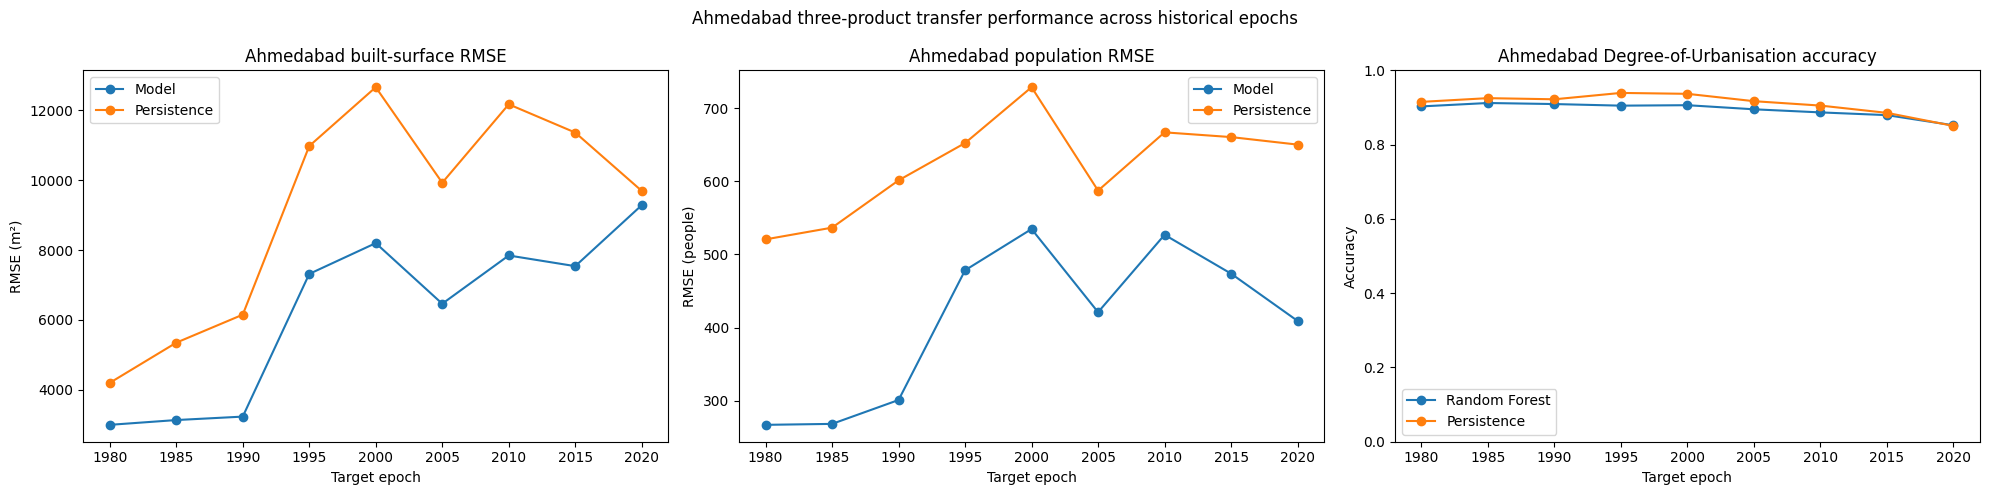

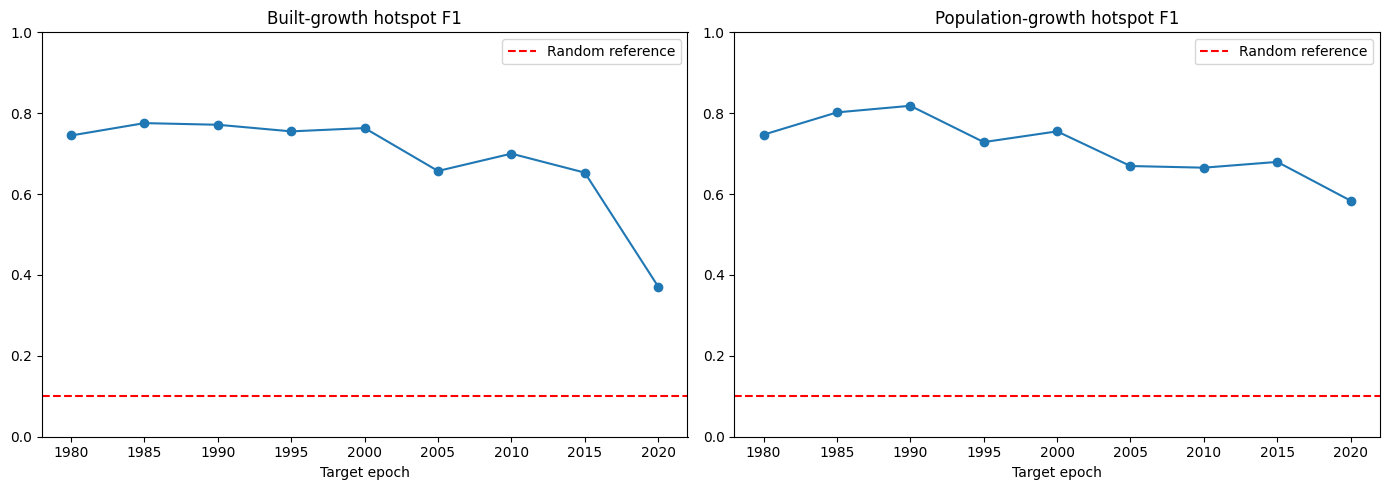

CELL 7: SUCCESS


In [36]:
# ============================================================
# CELL 7: ALL-EPOCH PERFORMANCE TREND FIGURES
# ============================================================
metric_data = pd.DataFrame([
    {
        'to_epoch': record['to_epoch'],
        'built_rmse': record['built_model']['rmse'],
        'built_persistence_rmse': record['built_persistence']['rmse'],
        'built_r2': record['built_model']['r2'],
        'built_hotspot_f1': record['built_hotspot_f1'],
        'population_rmse': record['population_model']['rmse'],
        'population_persistence_rmse': record['population_persistence']['rmse'],
        'population_r2': record['population_model']['r2'],
        'population_hotspot_f1': record['population_hotspot_f1'],
        'smod_accuracy': record['smod_accuracy'],
        'smod_persistence_accuracy': record['smod_persistence_accuracy'],
    }
    for record in RESULTS['metrics']
])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_rmse, marker='o', label='Model')
axes[0].plot(metric_data.to_epoch, metric_data.built_persistence_rmse, marker='o', label='Persistence')
axes[0].set_title('Ahmedabad built-surface RMSE')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylabel('RMSE (m²)')
axes[0].legend()

axes[1].plot(metric_data.to_epoch, metric_data.population_rmse, marker='o', label='Model')
axes[1].plot(metric_data.to_epoch, metric_data.population_persistence_rmse, marker='o', label='Persistence')
axes[1].set_title('Ahmedabad population RMSE')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylabel('RMSE (people)')
axes[1].legend()

axes[2].plot(metric_data.to_epoch, metric_data.smod_accuracy, marker='o', label='Random Forest')
axes[2].plot(metric_data.to_epoch, metric_data.smod_persistence_accuracy, marker='o', label='Persistence')
axes[2].set_title('Ahmedabad Degree-of-Urbanisation accuracy')
axes[2].set_xlabel('Target epoch')
axes[2].set_ylabel('Accuracy')
axes[2].set_ylim(0, 1)
axes[2].legend()

fig.suptitle('Ahmedabad three-product transfer performance across historical epochs')
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'ahmedabad_three_product_performance_by_epoch.png', dpi=200)
plt.show()
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_hotspot_f1, marker='o')
axes[0].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[0].set_title('Built-growth hotspot F1')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[1].plot(metric_data.to_epoch, metric_data.population_hotspot_f1, marker='o')
axes[1].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[1].set_title('Population-growth hotspot F1')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'ahmedabad_growth_hotspot_f1_by_epoch.png', dpi=200)
plt.show()
plt.close()

print('CELL 7: SUCCESS')

In [37]:
# ============================================================
# CELL 8: ACTUAL-VS-PREDICTED SCATTERS, RESIDUALS, CONFUSION
# Produces one figure set for each of the nine target epochs.
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    specifications = [
        (
            'actual_next_built_surface_m2',
            'predicted_built_surface_m2',
            'Built surface',
            'm²',
        ),
        (
            'actual_next_population',
            'predicted_population',
            'Population',
            'people',
        ),
    ]
    for axis, (actual_column, predicted_column, title, unit) in zip(axes, specifications):
        actual = data[actual_column].astype(float)
        predicted = data[predicted_column].astype(float)
        minimum = min(actual.min(), predicted.min())
        maximum = max(actual.max(), predicted.max())
        axis.scatter(actual, predicted, s=7, alpha=0.28)
        axis.plot([minimum, maximum], [minimum, maximum], color='red', label='Perfect prediction')
        residual = predicted - actual
        rmse = np.sqrt(np.mean(residual ** 2))
        r2 = 1 - np.sum(residual ** 2) / np.sum((actual - actual.mean()) ** 2)
        axis.set_title(f'{title}: R²={r2:.4f}, RMSE={rmse:,.1f}')
        axis.set_xlabel(f'Actual {target_epoch} ({unit})')
        axis.set_ylabel(f'Predicted {target_epoch} ({unit})')
        axis.legend()
    fig.suptitle(f'Ahmedabad {source_epoch}→{target_epoch}: actual vs predicted')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_actual_vs_predicted.png',
        dpi=200,
    )
    plt.close()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(data['built_error_m2'], bins=60)
    axes[0].axvline(0, color='red')
    axes[0].set_title('Built-surface errors')
    axes[0].set_xlabel('Predicted - actual (m²)')
    axes[1].hist(data['population_error'], bins=60)
    axes[1].axvline(0, color='red')
    axes[1].set_title('Population errors')
    axes[1].set_xlabel('Predicted - actual (people)')
    fig.suptitle(f'Ahmedabad {source_epoch}→{target_epoch}: error distributions')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_error_distributions.png',
        dpi=200,
    )
    plt.close()

    classes = sorted(
        set(data.actual_smod_class.astype(str))
        | set(data.predicted_smod_class.astype(str)),
        key=lambda value: int(float(value)),
    )
    confusion = pd.crosstab(
        data.actual_smod_class.astype(str),
        data.predicted_smod_class.astype(str),
    ).reindex(index=classes, columns=classes, fill_value=0)
    fig, axis = plt.subplots(figsize=(9, 7))
    image = axis.imshow(confusion.values, cmap='Blues')
    axis.set_xticks(range(len(classes)), classes, rotation=45)
    axis.set_yticks(range(len(classes)), classes)
    axis.set_xlabel('Predicted SMOD class')
    axis.set_ylabel('Actual SMOD class')
    axis.set_title(f'Ahmedabad SMOD confusion matrix, {target_epoch}')
    fig.colorbar(image, ax=axis)
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / f'ahmedabad_smod_confusion_{target_epoch}.png', dpi=200)
    plt.close()

print('Per-epoch scatter/residual/confusion figures created: 27')
print('CELL 8: SUCCESS')

Per-epoch scatter/residual/confusion figures created: 27
CELL 8: SUCCESS


In [38]:
# ============================================================
# CELL 9: SPATIAL THREE-PRODUCT MAPS FOR ALL NINE TARGET EPOCHS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    if len(data) != 4900:
        raise RuntimeError(f'{target_epoch}: expected 4,900 rows.')

    def pivot(column):
        return data.pivot(
            index='grid_1km_row',
            columns='grid_1km_col',
            values=column,
        ).sort_index(ascending=False)

    specifications = [
        (
            'Built surface',
            pivot('actual_next_built_surface_m2'),
            pivot('predicted_built_surface_m2'),
            'YlOrRd',
        ),
        (
            'Population',
            pivot('actual_next_population'),
            pivot('predicted_population'),
            'viridis',
        ),
        (
            'Degree of Urbanisation',
            pivot('actual_smod_class'),
            pivot('predicted_smod_class'),
            'tab20',
        ),
    ]

    figure, axes = plt.subplots(3, 3, figsize=(18, 16))
    for row_index, (name, actual_map, predicted_map, color_map) in enumerate(specifications):
        actual_map = actual_map.astype(float)
        predicted_map = predicted_map.astype(float)
        error_map = predicted_map - actual_map

        if name == 'Degree of Urbanisation':
            minimum = min(np.nanmin(actual_map), np.nanmin(predicted_map))
            maximum = max(np.nanmax(actual_map), np.nanmax(predicted_map))
        else:
            pooled = np.concatenate([
                actual_map.values.ravel(),
                predicted_map.values.ravel(),
            ])
            minimum = np.nanpercentile(pooled, 1)
            maximum = np.nanpercentile(pooled, 99)

        image = axes[row_index, 0].imshow(
            actual_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 0].set_title(f'Actual {name}')
        figure.colorbar(image, ax=axes[row_index, 0], fraction=0.046)

        image = axes[row_index, 1].imshow(
            predicted_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 1].set_title(f'Predicted {name}')
        figure.colorbar(image, ax=axes[row_index, 1], fraction=0.046)

        error_limit = max(
            abs(np.nanpercentile(error_map.values, 1)),
            abs(np.nanpercentile(error_map.values, 99)),
            1,
        )
        image = axes[row_index, 2].imshow(
            error_map, cmap='coolwarm', vmin=-error_limit, vmax=error_limit
        )
        axes[row_index, 2].set_title(f'{name} error')
        figure.colorbar(image, ax=axes[row_index, 2], fraction=0.046)

        for axis in axes[row_index]:
            axis.set_axis_off()

    figure.suptitle(
        f'Ahmedabad {source_epoch}→{target_epoch}: actual vs predicted three-product comparison',
        fontsize=16,
    )
    plt.tight_layout()
    output_path = SPATIAL_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_three_product_spatial.png'
    plt.savefig(output_path, dpi=180, bbox_inches='tight')
    plt.close()

print('Three-product spatial figures created:', len(list(SPATIAL_ROOT.glob('*three_product_spatial.png'))))
print('CELL 9: SUCCESS')

Three-product spatial figures created: 9
CELL 9: SUCCESS


In [39]:
# ============================================================
# CELL 10: BUILT AND POPULATION GROWTH-HOTSPOT MAPS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    hotspot_count = 490

    for prefix, actual_column, predicted_column, title in [
        (
            'built',
            'actual_built_growth_m2',
            'predicted_built_growth_m2',
            'Built-surface growth',
        ),
        (
            'population',
            'actual_population_change',
            'predicted_population_change',
            'Population growth',
        ),
    ]:
        actual_indices = set(
            data.nlargest(hotspot_count, actual_column).index
        )
        predicted_indices = set(
            data.nlargest(hotspot_count, predicted_column).index
        )
        correct_indices = actual_indices & predicted_indices

        data['actual_hotspot'] = data.index.isin(actual_indices)
        data['predicted_hotspot'] = data.index.isin(predicted_indices)
        data['correct_hotspot'] = data.index.isin(correct_indices)

        def pivot(column):
            return data.pivot(
                index='grid_1km_row',
                columns='grid_1km_col',
                values=column,
            ).sort_index(ascending=False)

        figure, axes = plt.subplots(1, 3, figsize=(16, 5))
        maps = [
            ('Actual top 10%', pivot('actual_hotspot'), 'Reds'),
            ('Predicted top 10%', pivot('predicted_hotspot'), 'Blues'),
            ('Correct overlap', pivot('correct_hotspot'), 'Greens'),
        ]
        for axis, (map_title, map_data, color_map) in zip(axes, maps):
            axis.imshow(map_data, cmap=color_map, vmin=0, vmax=1)
            axis.set_title(map_title)
            axis.set_axis_off()

        hotspot_f1 = len(correct_indices) / float(hotspot_count)
        figure.suptitle(
            f'Ahmedabad {source_epoch}→{target_epoch} {title} hotspots, F1={hotspot_f1:.2%}'
        )
        plt.tight_layout()
        plt.savefig(
            SPATIAL_ROOT / f'ahmedabad_{source_epoch}_{target_epoch}_{prefix}_hotspots.png',
            dpi=180,
            bbox_inches='tight',
        )
        plt.close()

print('Hotspot figures created:', len(list(SPATIAL_ROOT.glob('*hotspots.png'))))
print('CELL 10: SUCCESS')

Hotspot figures created: 18
CELL 10: SUCCESS


In [40]:
# ============================================================
# CELL 11: SAVE FINAL MANIFEST AND COMPLETION GATE
# ============================================================
primary_result = next(
    record for record in RESULTS['metrics'] if record['to_epoch'] == 2020
)

manifest = {
    'created_at_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    'city': 'Ahmedabad Metropolitan Region',
    'city_slug': 'ahmedabad',
    'ahmedabad_used_in_training': False,
    'actual_epochs': ACTUAL_EPOCHS,
    'prediction_target_epochs': TARGET_EPOCHS,
    'baseline_epoch_without_prediction': 1975,
    'prediction_comparisons': 9,
    'rows_per_comparison': 4900,
    'total_prediction_rows': 44100,
    'models': {
        'built_surface': {
            'type': 'Linear Regression',
            'path': BUILT_MODEL,
            'target': 'built_surface_total_m2',
        },
        'population': {
            'type': 'Linear Regression',
            'path': POPULATION_MODEL,
            'target': 'population_total',
        },
        'degree_of_urbanisation': {
            'type': 'Random Forest Classifier',
            'path': SMOD_MODEL,
            'target': 'smod_class',
        },
    },
    'primary_unseen_city_unseen_time_test': '2015->2020',
    'primary_2015_2020_metrics': primary_result,
    'hdfs_outputs': {
        'transitions': AHMEDABAD_THREE_TARGET_TRANSITIONS,
        'cell_predictions': CELL_PREDICTIONS,
        'summary_tables': SUMMARY_TABLES,
    },
    'drive_output': str(ARTIFACT_ROOT),
    'figures': len(list(FIGURE_ROOT.rglob('*.png'))),
    'source_datasets_modified': False,
}

manifest_path = ARTIFACT_ROOT / 'ahmedabad_three_product_evaluation_manifest.json'
manifest_path.write_text(
    json.dumps(manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('Ahmedabad actual epochs available: 10/10')
print('Five-year prediction comparisons: 9/9')
print('1975 retained as observed baseline: YES')
print('Built-surface predictions evaluated: COMPLETE')
print('Population predictions evaluated: COMPLETE')
print('Degree-of-Urbanisation predictions evaluated: COMPLETE')
print('Persistence comparisons: COMPLETE')
print('All-epoch metrics and CSV exports: COMPLETE')
print('All-epoch actual-vs-predicted figures: COMPLETE')
print('All-epoch spatial figures: COMPLETE')
print('All-epoch growth-hotspot figures: COMPLETE')
print('Primary 2015->2020 transfer test: COMPLETE')
print('Ahmedabad used in training: NO')
print('Source HDFS datasets modified: NO')
print('NOTEBOOK_18_AHMEDABAD_THREE_PRODUCT_EVALUATION_SUCCESS')
print('CELL 11: SUCCESS')

Ahmedabad actual epochs available: 10/10
Five-year prediction comparisons: 9/9
1975 retained as observed baseline: YES
Built-surface predictions evaluated: COMPLETE
Population predictions evaluated: COMPLETE
Degree-of-Urbanisation predictions evaluated: COMPLETE
Persistence comparisons: COMPLETE
All-epoch metrics and CSV exports: COMPLETE
All-epoch actual-vs-predicted figures: COMPLETE
All-epoch spatial figures: COMPLETE
All-epoch growth-hotspot figures: COMPLETE
Primary 2015->2020 transfer test: COMPLETE
Ahmedabad used in training: NO
Source HDFS datasets modified: NO
NOTEBOOK_18_AHMEDABAD_THREE_PRODUCT_EVALUATION_SUCCESS
CELL 11: SUCCESS


In [41]:
# ============================================================
# FINAL DISPLAY: CONSISTENT ACTUAL / PREDICTED / ERROR MAPS
# Displays and saves one 3 x 3 figure for each of nine transitions.
# ============================================================
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Patch
SMOD_ORDER=[0,10,11,12,13,21,22,23,30]
SMOD_LABELS={0:'No data',10:'Water',11:'Very low-density rural',12:'Low-density rural',13:'Rural cluster',21:'Suburban / peri-urban',22:'Semi-dense urban cluster',23:'Dense urban cluster',30:'Urban centre'}
SMOD_COLORS=['#d9d9d9','#4f9bd9','#ffffcc','#c7e9b4','#41ab5d','#fdae61','#f46d43','#d73027','#7f0000']
SMOD_MAP={v:i for i,v in enumerate(SMOD_ORDER)};SMOD_CMAP=ListedColormap(SMOD_COLORS);SMOD_NORM=BoundaryNorm(np.arange(-.5,len(SMOD_ORDER)+.5,1),SMOD_CMAP.N);AGREE=ListedColormap(['#d73027','#1a9850'])
def grid(d,c):
 g=d.pivot(index='grid_1km_row',columns='grid_1km_col',values=c).sort_index(ascending=False)
 if g.shape!=(70,70):raise RuntimeError(f'{c}: expected 70 x 70, found {g.shape}')
 return g
def reg(a,p):
 a=np.asarray(a,float);p=np.asarray(p,float);m=np.isfinite(a)&np.isfinite(p);a=a[m];p=p[m];e=p-a;den=np.sum((a-a.mean())**2)
 return {'mae':np.mean(abs(e)),'rmse':np.sqrt(np.mean(e**2)),'r2':np.nan if den==0 else 1-np.sum(e**2)/den,'bias':np.mean(e)}
def rng(a,p):
 z=np.concatenate([a.values.ravel(),p.values.ravel()]);z=z[np.isfinite(z)];return 0,max(float(np.nanpercentile(z,99.5)),1)
def elim(e):
 z=np.abs(e.values.ravel());z=z[np.isfinite(z)];return max(float(np.nanpercentile(z,99)),1)
outdir=ARTIFACT_ROOT/'figures'/'consistent_spatial';outdir.mkdir(parents=True,exist_ok=True);inventory=[]
for target in TARGET_EPOCHS:
 source=target-5;path=ARTIFACT_ROOT/f'ahmedabad_{source}_{target}_three_product_predictions.csv';d=pd.read_csv(path)
 if len(d)!=4900:raise RuntimeError(f'{path}: expected 4900 rows')
 bm=reg(d.actual_next_built_surface_m2,d.predicted_built_surface_m2);pm=reg(d.actual_next_population,d.predicted_population)
 ba,bp=grid(d,'actual_next_built_surface_m2'),grid(d,'predicted_built_surface_m2');pa,pp=grid(d,'actual_next_population'),grid(d,'predicted_population');sa_raw,sp_raw=grid(d,'actual_smod_class'),grid(d,'predicted_smod_class');sa=sa_raw.replace(SMOD_MAP).astype(float);sp=sp_raw.replace(SMOD_MAP).astype(float);agree=(sa_raw==sp_raw).astype(int);sacc=float(agree.values.mean());pacc=float((d.smod_class.astype(str)==d.actual_smod_class.astype(str)).mean())
 fig,ax=plt.subplots(3,3,figsize=(20,17));bmin,bmax=rng(ba,bp);pmin,pmax=rng(pa,pp);be=bp-ba;pe=pp-pa
 specs=[(ba,bp,be,'Built surface','YlOrRd',bmin,bmax,elim(be),'m²',bm),(pa,pp,pe,'Population','viridis',pmin,pmax,elim(pe),'people',pm)]
 for r,(a,p,e,name,cmap,vmin,vmax,limit,unit,m) in enumerate(specs):
  im=ax[r,0].imshow(a,cmap=cmap,vmin=vmin,vmax=vmax);ax[r,0].set_title(f'Actual {name} {target}');fig.colorbar(im,ax=ax[r,0],fraction=.046,label=unit)
  im=ax[r,1].imshow(p,cmap=cmap,vmin=vmin,vmax=vmax);ax[r,1].set_title(f'Predicted {name} {target}');fig.colorbar(im,ax=ax[r,1],fraction=.046,label=unit)
  im=ax[r,2].imshow(e,cmap='coolwarm',vmin=-limit,vmax=limit);ax[r,2].set_title(f'{name} error\npredicted - actual');fig.colorbar(im,ax=ax[r,2],fraction=.046,label=f'Error ({unit})')
  ax[r,1].text(.5,-.08,f'MAE={m["mae"]:,.1f} | RMSE={m["rmse"]:,.1f} | R²={m["r2"]:.4f} | Bias={m["bias"]:+,.1f}',transform=ax[r,1].transAxes,ha='center',va='top',fontsize=10,bbox={'boxstyle':'round,pad=.3','facecolor':'white','alpha':.85})
 ax[2,0].imshow(sa,cmap=SMOD_CMAP,norm=SMOD_NORM);ax[2,0].set_title(f'Actual Degree of Urbanisation {target}');ax[2,1].imshow(sp,cmap=SMOD_CMAP,norm=SMOD_NORM);ax[2,1].set_title(f'Predicted Degree of Urbanisation {target}');ax[2,2].imshow(agree,cmap=AGREE,vmin=0,vmax=1);ax[2,2].set_title('SMOD agreement\nred = incorrect, green = correct');ax[2,1].text(.5,-.08,f'Random Forest accuracy={sacc:.2%} | Persistence={pacc:.2%} | Difference={sacc-pacc:+.2%}',transform=ax[2,1].transAxes,ha='center',va='top',fontsize=10,bbox={'boxstyle':'round,pad=.3','facecolor':'white','alpha':.85})
 for row in ax:
  for a in row:a.set_axis_off()
 fig.legend(handles=[Patch(facecolor=SMOD_COLORS[i],label=f'{v}: {SMOD_LABELS[v]}') for i,v in enumerate(SMOD_ORDER)],loc='lower center',ncol=3,fontsize=9,bbox_to_anchor=(.42,.004),title='Degree-of-Urbanisation classes');fig.legend(handles=[Patch(facecolor='#1a9850',label='Correct'),Patch(facecolor='#d73027',label='Incorrect')],loc='lower center',ncol=2,fontsize=9,bbox_to_anchor=(.82,.025),title='Classification')
 fig.suptitle(f'Ahmedabad {source}→{target}: actual versus predicted GHSL products',fontsize=18,y=.995);plt.tight_layout(rect=[0,.105,1,.97]);out=outdir/f'ahmedabad_{source}_{target}_consistent_three_product_comparison.png';plt.savefig(out,dpi=200,bbox_inches='tight');plt.show();plt.close(fig);inventory.append({'from_epoch':source,'to_epoch':target,'path':str(out),'built_metrics':bm,'population_metrics':pm,'smod_accuracy':sacc,'smod_persistence_accuracy':pacc})
(ARTIFACT_ROOT/'consistent_spatial_figure_inventory.json').write_text(json.dumps(inventory,indent=2,sort_keys=True)+'\n')
print('Consistent Ahmedabad figures:',len(inventory));print('AHMEDABAD CONSISTENT THREE-PRODUCT FIGURES: SUCCESS')

Output hidden; open in https://colab.research.google.com to view.

In [42]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/"
    "GHSL_Urban_Growth_Model/"
    "ahmedabad_three_product_evaluation_v1"
)

if not root.is_dir():
    raise FileNotFoundError(
        "Ahmedabad results folder is missing: "
        + str(root)
    )

files = sorted(
    path
    for path in root.rglob("*")
    if path.is_file()
)

print("Ahmedabad results folder:", root)
print("Files found:", len(files))
print()

for path in files:
    print(
        path.relative_to(root),
        "|",
        f"{path.stat().st_size / 1024:.1f} KB",
    )

required = [
    root / "ahmedabad_three_product_metrics.csv",
    root / "ahmedabad_three_product_metrics.json",
    root / "ahmedabad_2015_2020_three_product_predictions.csv",
    root / "ahmedabad_three_product_evaluation_manifest.json",
    root / "figures" / "consistent_spatial"
         / "ahmedabad_2015_2020_consistent_three_product_comparison.png",
]

missing = [
    str(path)
    for path in required
    if not path.is_file()
]

if missing:
    raise RuntimeError(
        "Missing expected Ahmedabad artifacts:\n"
        + "\n".join(missing)
    )

print()
print("AHMEDABAD GOOGLE DRIVE RESULTS INVENTORY: PASS")

Ahmedabad results folder: /content/drive/MyDrive/GHSL_Urban_Growth_Model/ahmedabad_three_product_evaluation_v1
Files found: 80

ahmedabad_1975_1980_three_product_predictions.csv | 1486.7 KB
ahmedabad_1980_1985_three_product_predictions.csv | 1489.3 KB
ahmedabad_1985_1990_three_product_predictions.csv | 1491.1 KB
ahmedabad_1990_1995_three_product_predictions.csv | 1492.7 KB
ahmedabad_1995_2000_three_product_predictions.csv | 1495.7 KB
ahmedabad_2000_2005_three_product_predictions.csv | 1499.9 KB
ahmedabad_2005_2010_three_product_predictions.csv | 1502.2 KB
ahmedabad_2010_2015_three_product_predictions.csv | 1502.8 KB
ahmedabad_2015_2020_three_product_predictions.csv | 1503.3 KB
ahmedabad_smod_confusion_all_epochs.csv | 3.2 KB
ahmedabad_three_product_evaluation_manifest.json | 2.5 KB
ahmedabad_three_product_metrics.csv | 3.5 KB
ahmedabad_three_product_metrics.json | 36.2 KB
cell_prediction_export_manifest.json | 2.2 KB
consistent_spatial_figure_inventory.json | 5.8 KB
figures/ahmedabad_1